In [1]:
import sys, cv2, mediapipe as mp
print(sys.executable, cv2.__version__, mp.__version__)
print(mp.solutions.holistic)


F:\anaconda\envs\isl-prep\python.exe 5.0.0 0.10.14
<module 'mediapipe.python.solutions.holistic' from 'F:\\anaconda\\envs\\isl-prep\\lib\\site-packages\\mediapipe\\python\\solutions\\holistic.py'>


In [2]:
import numpy as np, pandas as pd, cv2
from pathlib import Path

N_POSE, N_FACE, N_HAND = 33, 468, 21
SL = {"pose": slice(0, 132), "face": slice(132, 1536), "lh": slice(1536, 1599), "rh": slice(1599, 1662)}
VIDEO_EXT = {".mov", ".mp4", ".avi", ".mkv", ".m4v"}

def scan_include(root):
    rows = []
    for p in sorted(Path(root).rglob("*")):
        if p.suffix.lower() in VIDEO_EXT:
            label = p.parent.name.split(".", 1)[-1].strip().lower()
            rows.append(dict(path=str(p), category=p.parent.parent.name, label=label, file=p.name))
    return pd.DataFrame(rows)

def frame_to_vector(res):
    def arr(lms, n, with_vis=False):
        if lms is None: return np.zeros(n * (4 if with_vis else 3), np.float32)
        if with_vis: return np.array([[p.x, p.y, p.z, p.visibility] for p in lms.landmark], np.float32).ravel()
        return np.array([[p.x, p.y, p.z] for p in lms.landmark], np.float32).ravel()
    return np.concatenate([arr(res.pose_landmarks, N_POSE, True), arr(res.face_landmarks, N_FACE),
                           arr(res.left_hand_landmarks, N_HAND), arr(res.right_hand_landmarks, N_HAND)])

def extract_video_landmarks(path, target_fps=None, model_complexity=1):
    import mediapipe as mp
    hol = mp.solutions.holistic.Holistic(static_image_mode=False, model_complexity=model_complexity,
                                         min_detection_confidence=0.5, min_tracking_confidence=0.5)
    cap = cv2.VideoCapture(str(path)); src_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    step = max(1, int(round(src_fps / target_fps))) if target_fps else 1
    out, i = [], 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if i % step == 0: out.append(frame_to_vector(hol.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))))
        i += 1
    cap.release(); hol.close()
    return np.stack(out) if out else np.zeros((0, 1662), np.float32)

def quality_row(seq):
    T = len(seq)
    if T == 0: return dict(n_frames=0, lh_rate=0, rh_rate=0, any_hand_rate=0, pose_rate=0)
    lh = np.abs(seq[:, SL["lh"]]).sum(1) > 0; rh = np.abs(seq[:, SL["rh"]]).sum(1) > 0
    pose = np.abs(seq[:, SL["pose"]]).sum(1) > 0
    return dict(n_frames=T, lh_rate=lh.mean(), rh_rate=rh.mean(), any_hand_rate=(lh | rh).mean(), pose_rate=pose.mean())

DATA_ROOT = Path("F:/ISL/INCLUDE")
catalog = scan_include(DATA_ROOT)
print(len(catalog), "videos,", catalog.label.nunique(), "signs,", catalog.category.nunique(), "categories")
print(catalog.groupby("category").size())

seq = extract_video_landmarks(catalog.path.iloc[0])
print(seq.shape)                 # expect (frames, 1662)
print(quality_row(seq))

356 videos, 18 signs, 3 categories
category
4. Bird        5
Animals      161
Greetings    190
dtype: int64


F:\anaconda\envs\isl-prep\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


(117, 1662)
{'n_frames': 117, 'lh_rate': np.float64(0.27350427350427353), 'rh_rate': np.float64(0.7948717948717948), 'any_hand_rate': np.float64(0.9145299145299145), 'pose_rate': np.float64(1.0)}


In [3]:
bird = catalog[catalog.category == "4. Bird"]
print(bird.path.tolist()[:3])
print(list(Path("F:/ISL/INCLUDE/Animals/4. Bird").iterdir())[:8])

['F:\\ISL\\INCLUDE\\Animals\\4. Bird\\Extra\\MVI_3041.MOV', 'F:\\ISL\\INCLUDE\\Animals\\4. Bird\\Extra\\MVI_3042.MOV', 'F:\\ISL\\INCLUDE\\Animals\\4. Bird\\Extra\\MVI_3043.MOV']
[WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/Extra'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_2987.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_2988.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_2989.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_3011.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_3012.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_3013.MOV'), WindowsPath('F:/ISL/INCLUDE/Animals/4. Bird/MVI_3037.MOV')]


In [4]:
def scan_include(root):
    root = Path(root); rows = []
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() in VIDEO_EXT:
            rel = p.relative_to(root).parts            # (Category, sign folder, ..., file)
            sign = next((s for s in rel[1:-1] if s.split(".")[0].strip().isdigit()), rel[-2] if len(rel) > 2 else "unknown")
            rows.append(dict(path=str(p), category=rel[0], label=sign.split(".", 1)[-1].strip().lower(), file=p.name))
    return pd.DataFrame(rows)

catalog = scan_include(DATA_ROOT)
print(len(catalog), "videos,", catalog.label.nunique(), "signs,", catalog.category.nunique(), "categories")
print(catalog.groupby("category").size())
print(catalog.groupby("label").size().sort_values())      # videos per sign


356 videos, 17 signs, 2 categories
category
Animals      166
Greetings    190
dtype: int64
label
animal            20
cat               20
fish              20
dog               20
horse             20
mouse             20
cow               21
alright           21
hello             21
good night        21
good evening      21
good morning      21
how are you       21
pleased           21
thank you         21
good afternoon    22
bird              25
dtype: int64


In [5]:
seq = extract_video_landmarks(catalog.path.iloc[0])
print(seq.shape)             # expect (frames, 1662)
print(quality_row(seq))

F:\anaconda\envs\isl-prep\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


(117, 1662)
{'n_frames': 117, 'lh_rate': np.float64(0.27350427350427353), 'rh_rate': np.float64(0.7948717948717948), 'any_hand_rate': np.float64(0.9145299145299145), 'pose_rate': np.float64(1.0)}


In [6]:
import numpy as np
CACHE = Path("F:/ISL/cache_landmarks"); CACHE.mkdir(parents=True, exist_ok=True)

raw_seqs = []
for i, r in catalog.iterrows():
    f = CACHE / f"{i:05d}_{Path(r.path).stem}.npy"
    if not f.exists():
        np.save(f, extract_video_landmarks(r.path, target_fps=25).astype(np.float16))
    raw_seqs.append(np.load(f).astype(np.float32))
    if i % 20 == 0: print(i, "of", len(catalog))
print("done:", len(raw_seqs))

0 of 356
20 of 356
40 of 356
60 of 356
80 of 356
100 of 356
120 of 356
140 of 356
160 of 356
180 of 356
200 of 356
220 of 356
240 of 356
260 of 356
280 of 356
300 of 356
320 of 356
340 of 356
done: 356


In [7]:
from sklearn.model_selection import train_test_split
catalog["id"] = catalog.index
tr, tmp = train_test_split(catalog.id, test_size=0.3, stratify=catalog.label, random_state=42)
va, te = train_test_split(tmp, test_size=0.5, stratify=catalog.loc[tmp, "label"], random_state=42)
catalog["split"] = "train"; catalog.loc[va, "split"] = "val"; catalog.loc[te, "split"] = "test"
print(catalog.split.value_counts())



split
train    249
test      54
val       53
Name: count, dtype: int64


In [8]:
print(len(raw_seqs), "sequences")     


356 sequences


In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
T_FIXED = 30
meta = catalog.copy()
meta["n_frames"] = [len(s) for s in raw_seqs]

def longest_run(mask):
    best = cur = 0
    for m in mask:
        cur = cur + 1 if m else 0; best = max(best, cur)
    return best

def quality_row(seq):
    lh = np.abs(seq[:, SL["lh"]]).sum(1) > 0; rh = np.abs(seq[:, SL["rh"]]).sum(1) > 0
    pose = np.abs(seq[:, SL["pose"]]).sum(1) > 0
    return dict(lh_rate=lh.mean(), rh_rate=rh.mean(), any_hand_rate=(lh | rh).mean(), pose_rate=pose.mean(), max_gap=longest_run(~(lh | rh)))

Q = pd.DataFrame([quality_row(s) for s in raw_seqs])
meta = pd.concat([meta.reset_index(drop=True), Q], axis=1)
meta["flag"] = (meta.any_hand_rate < 0.5) | (meta.n_frames < 15) | (meta.pose_rate < 0.9)
print(meta[["n_frames", "lh_rate", "rh_rate", "any_hand_rate", "pose_rate", "max_gap"]].describe().round(3))
print("flagged for review:", int(meta.flag.sum()), "of", len(meta))

       n_frames  lh_rate  rh_rate  any_hand_rate  pose_rate  max_gap
count   356.000  356.000  356.000        356.000      356.0  356.000
mean     74.051    0.836    0.766          0.898        1.0    3.868
std      15.742    0.211    0.144          0.146        0.0    5.845
min      41.000    0.000    0.155          0.155        1.0    0.000
25%      60.000    0.767    0.721          0.855        1.0    0.000
50%      75.000    0.889    0.805          0.941        1.0    2.000
75%      84.000    1.000    0.852          1.000        1.0    6.000
max     125.000    1.000    0.977          1.000        1.0   45.000
flagged for review: 11 of 356


In [10]:
N_POSE = 33
def fill_missing(seq):
    out = seq.copy()
    for key in ("pose", "face", "lh", "rh"):
        blk = out[:, SL[key]]; miss = np.abs(blk).sum(1) == 0
        if not miss.any() or miss.all(): continue
        idx = np.arange(len(blk)); good = ~miss
        for j in range(blk.shape[1]): blk[miss, j] = np.interp(idx[miss], idx[good], blk[good, j])
        out[:, SL[key]] = blk
    return out

def normalise(seq, eps=1e-6):
    out = seq.copy(); T = len(out)
    pose = out[:, SL["pose"]].reshape(T, N_POSE, 4)
    ls, rs = pose[:, 11, :3], pose[:, 12, :3]
    origin = (ls + rs) / 2
    width = np.linalg.norm((ls - rs)[:, :2], axis=1)
    scale = np.median(width[width > eps]) if (width > eps).any() else 1.0
    def tf(key, d):
        blk = out[:, SL[key]].reshape(T, -1, d); nz = np.abs(out[:, SL[key]]).sum(1) > 0
        blk[nz, :, :3] = (blk[nz, :, :3] - origin[nz, None, :]) / scale
        out[:, SL[key]] = blk.reshape(T, -1)
    tf("pose", 4); tf("face", 3); tf("lh", 3); tf("rh", 3)
    return out

def select_features(seq, mode="compact"):
    if mode == "full": return seq.astype(np.float32)
    T = len(seq); pose = seq[:, SL["pose"]].reshape(T, N_POSE, 4)[:, :25, :3].reshape(T, -1)
    return np.concatenate([pose, seq[:, SL["lh"]], seq[:, SL["rh"]]], 1).astype(np.float32)

def resample(seq, T=T_FIXED):
    n = len(seq)
    pos = np.linspace(0, n - 1, T); i0 = np.floor(pos).astype(int); i1 = np.minimum(i0 + 1, n - 1); w = (pos - i0)[:, None]
    return (seq[i0] * (1 - w) + seq[i1] * w).astype(np.float32)

def preprocess(seq, mode="compact", T=T_FIXED):
    return resample(select_features(normalise(fill_missing(seq)), mode), T)

X = np.stack([preprocess(s) for s in raw_seqs])
print("X shape:", X.shape)          # expect (356, 30, 201)

X shape: (356, 30, 201)


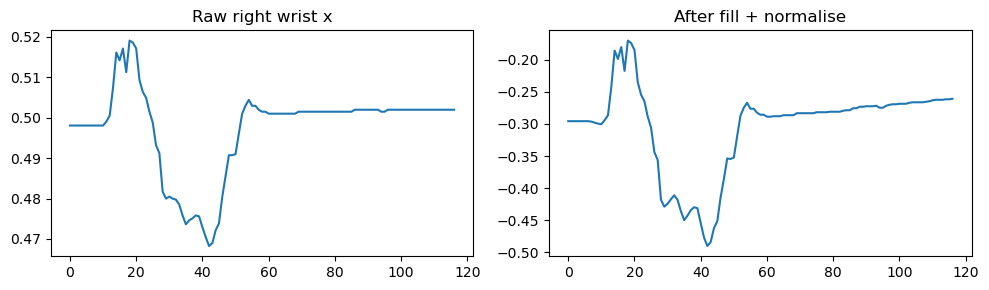

In [11]:
from pathlib import Path
out = Path("F:/ISL/processed"); out.mkdir(exist_ok=True)
y = meta.label.astype("category").cat.codes.values
np.savez_compressed(out / "include_animals_greetings_T30_compact.npz", X=X, y=y, split=meta.split.values,
                    classes=np.array(sorted(meta.label.unique())))
meta.to_csv(out / "metadata.csv", index=False)

i = 0; s = raw_seqs[i]; n = normalise(fill_missing(s))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(s[:, SL["pose"]].reshape(len(s), 33, 4)[:, 16, 0]); ax[0].set_title("Raw right wrist x")
ax[1].plot(n[:, SL["pose"]].reshape(len(n), 33, 4)[:, 16, 0]); ax[1].set_title("After fill + normalise")
plt.tight_layout(); plt.show()

In [12]:
import numpy as np
d = np.load("F:/ISL/processed/include_animals_greetings_T30_compact.npz", allow_pickle=True)
print({k: d[k].shape for k in d.files})
print(d["classes"])

{'X': (356, 30, 201), 'y': (356,), 'split': (356,), 'classes': (17,)}
['alright' 'animal' 'bird' 'cat' 'cow' 'dog' 'fish' 'good afternoon'
 'good evening' 'good morning' 'good night' 'hello' 'horse' 'how are you'
 'mouse' 'pleased' 'thank you']


In [13]:
print(meta.iloc[0][["category", "label", "file"]])        # which video the plot shows
print(len(catalog), "videos,", catalog.label.nunique(), "signs,", catalog.category.nunique(), "categories")
print(catalog.groupby("category").size())
print(catalog.groupby("label").size().sort_values())
print(meta[["n_frames", "lh_rate", "rh_rate", "any_hand_rate", "pose_rate", "max_gap"]].describe().round(3))
print("flagged:", int(meta.flag.sum()), "of", len(meta))
print(meta.split.value_counts())
print("X shape:", X.shape)

category         Animals
label                dog
file        MVI_2978.MOV
Name: 0, dtype: object
356 videos, 17 signs, 2 categories
category
Animals      166
Greetings    190
dtype: int64
label
animal            20
cat               20
fish              20
dog               20
horse             20
mouse             20
cow               21
alright           21
hello             21
good night        21
good evening      21
good morning      21
how are you       21
pleased           21
thank you         21
good afternoon    22
bird              25
dtype: int64
       n_frames  lh_rate  rh_rate  any_hand_rate  pose_rate  max_gap
count   356.000  356.000  356.000        356.000      356.0  356.000
mean     74.051    0.836    0.766          0.898        1.0    3.868
std      15.742    0.211    0.144          0.146        0.0    5.845
min      41.000    0.000    0.155          0.155        1.0    0.000
25%      60.000    0.767    0.721          0.855        1.0    0.000
50%      75.000    0.

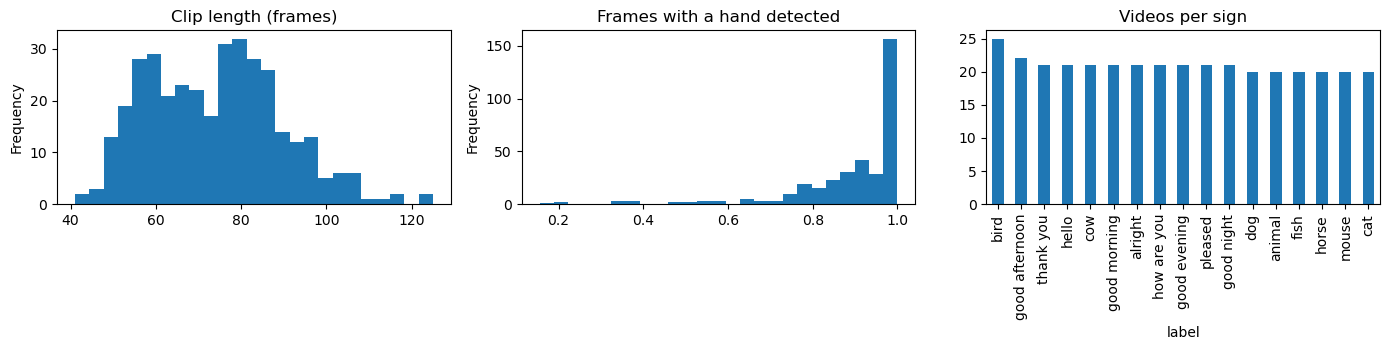

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
meta.n_frames.plot.hist(bins=25, ax=ax[0], title="Clip length (frames)")
meta.any_hand_rate.plot.hist(bins=25, ax=ax[1], title="Frames with a hand detected")
meta.label.value_counts().plot.bar(ax=ax[2], title="Videos per sign"); plt.tight_layout(); plt.show()